<a href="https://colab.research.google.com/github/freyebeans/ASU-assignments/blob/main/MAT422/HW3.7/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT422 Section 3.4 Logistic Regression
Michael Bishop

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(514)

## 3.7.1 Mathematical Formulation
A neural network is a collection of layers of nodes whose values are determined by the previous layers. For a layer indexed $l$, a vector $\textbf{a}^{(l)}$ representing the values in that layer is computed by $\textbf{a}^{(l)}=\sigma(\textbf{W}^{(l)}\textbf{a}^{(l-1)}+\textbf{b}^{(l)})$ where $\sigma$ is an activation function, $\textbf{W}^{(l)}$ is a matrix respresenting how much each node in layer $l-1$ contributes to each node in layer $l$, $\textbf{a}^{(l-1)}$ is a vector representing the values in layer $l-1$, and $\textbf{b}^{(l)}$ is a vector called the bias.

In [2]:
X = np.array([[0,0,0], [0,1,0], [1,0,0], [1,1,0], [0,0,1], [0,1,1], [1,0,1], [1,1,1]], dtype=float)
y = np.array([[0], [0], [0], [1], [0], [1], [1], [0]], dtype=float)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

W1 = rng.normal(scale=0.5, size=(3, 6))
b1 = np.zeros((1, 6))
W2 = rng.normal(scale=0.5, size=(6, 1))
b2 = np.zeros((1, 1))

def forward(X):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    return z1, a1, z2, a2

_, hidden, _, output = forward(X)
print("Input layer values:")
print(X)
print("Hidden layer values:")
print(hidden)
print("Initial predicted probabilities:")
print(output)

Input layer values:
[[0. 0. 0.]
 [0. 1. 0.]
 [1. 0. 0.]
 [1. 1. 0.]
 [0. 0. 1.]
 [0. 1. 1.]
 [1. 0. 1.]
 [1. 1. 1.]]
Hidden layer values:
[[ 0.      0.      0.      0.      0.      0.    ]
 [ 0.0233 -0.3292  0.3393 -0.1277 -0.0224 -0.1511]
 [-0.3466 -0.1896  0.191   0.1378  0.1487 -0.8558]
 [-0.326  -0.4884  0.498   0.0103  0.1268 -0.8916]
 [-0.4913  0.0453 -0.8268  0.5228 -0.6033  0.5185]
 [-0.4734 -0.2883 -0.6776  0.4233 -0.6173  0.3987]
 [-0.716  -0.1456 -0.7551  0.6162 -0.4994 -0.6064]
 [-0.7044 -0.4531 -0.559   0.5302 -0.516  -0.6939]]
Initial predicted probabilities:
[[0.5   ]
 [0.4875]
 [0.5109]
 [0.4997]
 [0.7423]
 [0.7573]
 [0.7632]
 [0.7695]]


As you can see above, depending on the input layer, the subsequent layers have different values, indicating the relation between each layer of the network.
## 3.7.2 Activation Functions
As mentioned previously, the values in each node are determined partially by the output of an activation function $\sigma$. This activation function is selected to absrtact the values of the nodes for a particular purpose.

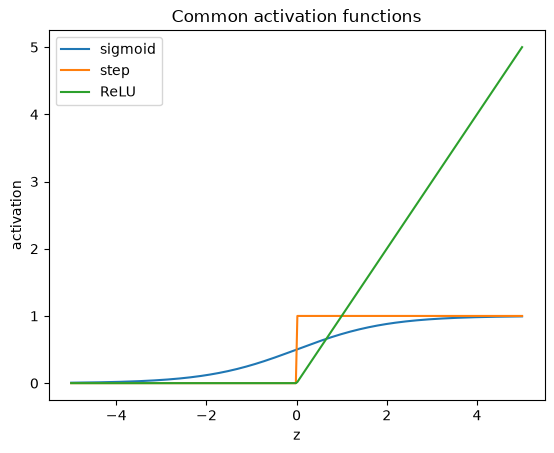

In [3]:
def step(z):
    return 1 - (z < 0)

def relu(z):
    return np.maximum(0, z)

z = np.linspace(-5, 5, 300)
plt.plot(z, sigmoid(z), label="sigmoid")
plt.plot(z, step(z), label="step")
plt.plot(z, relu(z), label="ReLU")
plt.xlabel("z")
plt.ylabel("activation")
plt.title("Common activation functions")
plt.legend()
plt.show()

As you can see above, different activation functions can fulfill different purposes, with the sigmoid being useful for probabilities and the step function being useful for classification (the sigmois is useful for this aswell).
## 3.7.3 Cost Function
The cost function is used to train the network to behave in a desirable way by minimizing the cost function. For the context in the examples, the binary cross entropy is good for a cost function.

In [4]:
def binary_cross_entropy(y_true, y_prob):
    eps = 1e-9
    return -np.mean(y_true*np.log(y_prob + eps) + (1-y_true)*np.log(1-y_prob + eps))

_, _, _, output = forward(X)
print("Initial binary cross-entropy =", binary_cross_entropy(y, output))
print("Target values:", y.ravel())
print("Initial predicted probabilities:", output.ravel())

Initial binary cross-entropy = 0.7678178302215589
Target values: [0. 0. 0. 1. 0. 1. 1. 0.]
Initial predicted probabilities: [0.5    0.4875 0.5109 0.4997 0.7423 0.7573 0.7632 0.7695]


As you can see above, the binary cross entropy of the untrained network could likely be lower, which is to be expected from an untrained network as it likley has undesirable behavior.
## 3.7.4 Backpropagation
Backpropegation is a process that minimizes the cost function across a network, which can be done using gradient descent. Since we will be using gradient descent, we must find the derivative of our activation functions.

In [5]:
z1, a1, z2, a2 = forward(X)
dz2 = (a2 - y) / len(X)
dW2 = a1.T @ dz2
db2 = dz2.sum(axis=0, keepdims=True)
da1 = dz2 @ W2.T
dz1 = da1 * (1 - np.tanh(z1)**2)
dW1 = X.T @ dz1
db1 = dz1.sum(axis=0, keepdims=True)

print("dW2 shape:", dW2.shape)
print("db2 shape:", db2.shape)
print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)
print("Backpropagation sends the output error backward through W2 and the tanh derivative.")

print("\nW2 shape:", W2.shape)
print("b2 shape:", b2.shape)
print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)

dW2 shape: (6, 1)
db2 shape: (1, 1)
dW1 shape: (3, 6)
db1 shape: (1, 6)
Backpropagation sends the output error backward through W2 and the tanh derivative.

W2 shape: (6, 1)
b2 shape: (1, 1)
W1 shape: (3, 6)
b1 shape: (1, 6)


As you can see the values of $dW_i$ and $db_i$ have the same shape as $W_i$ and $b_i$ which allows us to update $W_i$ and $b_i$ and use the gradient descent algorithm.
## 3.7.5 Backpropagation Algorithm
Using gradient descent, we update the weights and biases of the network to reach a desired behavior as determined by our cost function.

Final probabilities:
[[0.0005]
 [0.0005]
 [0.0005]
 [0.998 ]
 [0.0005]
 [0.9986]
 [0.9988]
 [0.0032]]
Final predictions:	 [0 0 0 1 0 1 1 0]
True values:		 [0 0 0 1 0 1 1 0]


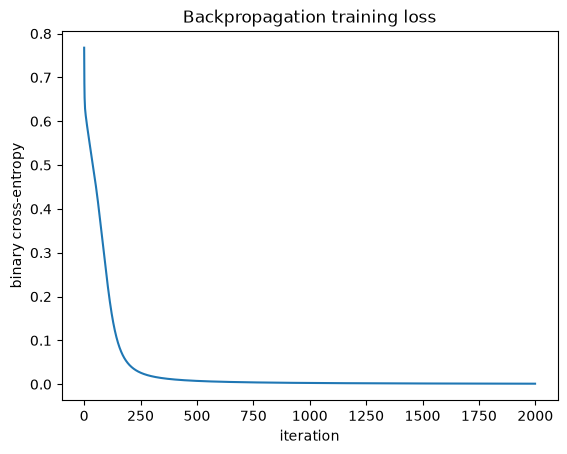

In [6]:
learning_rate = 0.6
losses = []
for step in range(2000):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    losses.append(binary_cross_entropy(y, a2))

    dz2 = (a2 - y) / len(X)
    dW2 = a1.T @ dz2
    db2 = dz2.sum(axis=0, keepdims=True)
    da1 = dz2 @ W2.T
    dz1 = da1 * (1 - np.tanh(z1)**2)
    dW1 = X.T @ dz1
    db1 = dz1.sum(axis=0, keepdims=True)

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

_, _, _, final_output = forward(X)
print("Final probabilities:")
print(final_output)
print("Final predictions:\t", (final_output > 0.5).astype(int).ravel())
print("True values:\t\t", y.astype(int).ravel())

plt.plot(losses)
plt.xlabel("iteration")
plt.ylabel("binary cross-entropy")
plt.title("Backpropagation training loss")
plt.show()

In the above example we trained the network to identify 3 dimensional vectors with 2 one values and 1 zero value. As you can see above, with each succesive iteration the network got better at identifying the vectors with 2 one values and 1 zero value.
## Reflection and Rubric Checklist
- I explained each concpet before and after the code.
- I verifed important claims numerically or visually.
- I changed and extended at least one example so that the notebook reflects my own work.
- I ran the notebook in its entirety without error.
- I saved the notebook from Google Colab directly to GitHub as per course instructions.